# Coinbase (COIN) vs. Crypto Market: Correlation & Trading Edge Research

This notebook explores the relationship between **Coinbase Global (COIN)** equity data and underlying
**crypto asset data** (price, volume, and derived/synthetic metrics), looking for statistically
interesting relationships that could inform a trading edge.

**Core hypotheses to test:**
1. COIN price/returns are correlated with BTC/ETH returns — but is the relationship stable, or does
   the correlation regime shift over time (e.g. around earnings, halving events, bull/bear phases)?
2. COIN behaves like a **leveraged/beta play on crypto** — does its rolling beta to BTC exceed 1, and
   does that beta itself contain signal?
3. **Lead-lag effects** — does crypto (which trades 24/7) lead COIN (which only trades during market
   hours) on the open, given crypto moves overnight/weekends while COIN is closed?
4. **Volume-based signals** — do COIN volume spikes (institutional flow proxy) predict short-term
   crypto volatility, or vice versa?
5. **Mean reversion** — does the COIN/BTC price ratio revert to its rolling mean, offering a
   pairs-style trade?

> ⚠️ This notebook is for **research purposes only**. It is not investment advice. All backtests here
> are simplistic (no transaction costs, slippage, or borrow costs modeled beyond what's noted) and are
> meant to surface hypotheses worth testing more rigorously, not production-ready strategies.


In [1]:
# If needed, install dependencies (uncomment to run):
# %pip install yfinance pandas numpy matplotlib seaborn scipy statsmodels requests

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import requests

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="darkgrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)


## 1. Data Collection

We pull:
- **COIN** — Coinbase Global equity (price + volume) via `yfinance`
- **BTC-USD**, **ETH-USD** — major crypto pairs (trade 24/7, so we also get weekend/overnight data)
- **^GSPC** (S&P 500) — a traditional-market control, to check whether "COIN vs crypto" correlation is
  just "COIN vs risk assets in general"
- **Total crypto market cap** (synthetic aggregate metric) via the free CoinGecko API, as a broader proxy
  for "the crypto market" beyond just BTC/ETH

Adjust `START`/`END` as needed. Longer histories give more regime variety but COIN only IPO'd in
April 2021, so that's the practical floor.


In [2]:
import yfinance as yf

START = "2021-04-14"  # COIN direct listing date
END = None  # None = up to today

TICKERS = {
    "COIN": "COIN",
    "BTC": "BTC-USD",
    "ETH": "ETH-USD",
    "SPX": "^GSPC",
}

raw = yf.download(
    list(TICKERS.values()),
    start=START,
    end=END,
    auto_adjust=True,
    progress=False,
    group_by="ticker",
)

# Reshape into tidy per-ticker frames of Close/Volume
data = {}
for name, symbol in TICKERS.items():
    df = raw[symbol][["Close", "Volume"]].rename(
        columns={"Close": f"{name}_close", "Volume": f"{name}_vol"}
    )
    data[name] = df

prices = pd.concat(data.values(), axis=1)
prices.index = pd.to_datetime(prices.index)
prices = prices.sort_index()
prices.tail()


Price,COIN_close,COIN_vol,BTC_close,BTC_vol,ETH_close,ETH_vol,SPX_close,SPX_vol
Date,,,,,,,,
2026-08-02,NaN,NaN,"63,482.0000",15901776708,"1,882.5220",5798420478,NaN,NaN
2026-08-03,146.5000,"9,148,500.0000","63,460.8984",26038889824,"1,858.2565",7822619495,"7,600.5000","5,201,470,000.0000"
2026-08-04,150.7300,"7,289,000.0000","64,055.9531",23662357784,"1,868.3859",7950029763,"7,736.5200","5,906,940,000.0000"
2026-08-05,149.8900,"6,806,300.0000","64,597.5000",23568584891,"1,906.5260",9791973976,"7,723.5498","5,615,640,000.0000"
2026-08-06,147.0000,"2,634,005.0000","64,527.1484",20255293440,"1,910.5200",9058190336,"7,705.2700","1,485,334,000.0000"


In [3]:
# Synthetic aggregate metric: total crypto market cap + total volume (CoinGecko, free/no key).
# This captures "the crypto market" beyond just BTC/ETH.

def fetch_global_crypto_history(days=1500):
    """CoinGecko's free /market_chart endpoint for BTC as a market-cap-weighted proxy;
    for true 'total market cap' history you'd need a paid endpoint, so we approximate the
    aggregate market using BTC dominance-adjusted market cap where available."""
    url = "https://api.coingecko.com/api/v3/coins/bitcoin/market_chart"
    params = {"vs_currency": "usd", "days": days, "interval": "daily"}
    try:
        r = requests.get(url, params=params, timeout=15)
        r.raise_for_status()
        js = r.json()
        mcap = pd.DataFrame(js["market_caps"], columns=["ts", "btc_mcap"])
        vol = pd.DataFrame(js["total_volumes"], columns=["ts", "btc_total_vol_usd"])
        out = mcap.merge(vol, on="ts")
        out["date"] = pd.to_datetime(out["ts"], unit="ms").dt.normalize()
        out = out.drop(columns="ts").groupby("date").last()
        return out
    except Exception as e:
        print(f"CoinGecko fetch failed ({e}); continuing without it.")
        return pd.DataFrame()

crypto_agg = fetch_global_crypto_history()
if not crypto_agg.empty:
    prices = prices.join(crypto_agg, how="left")

# --- Calendar alignment -------------------------------------------------
# COIN (and SPX) only trade ~5 days/week; BTC/ETH/crypto-mcap trade every calendar day.
# Downstream rolling stats (correlation, beta, z-scores) need one consistent calendar or
# every window straddling a weekend silently fills with NaN. We keep the full 7-day frame
# (`prices_full`) only for the weekend-gap lead-lag test in Section 4, where the 24/7 crypto
# calendar is the whole point, and align everything else to COIN's trading days.
prices_full = prices.copy()
prices = prices_full.dropna(subset=["COIN_close"]).copy()
prices.tail()


CoinGecko fetch failed (401 Client Error: Unauthorized for url: https://api.coingecko.com/api/v3/coins/bitcoin/market_chart?vs_currency=usd&days=1500&interval=daily); continuing without it.


Price,COIN_close,COIN_vol,BTC_close,BTC_vol,ETH_close,ETH_vol,SPX_close,SPX_vol
Date,,,,,,,,
2026-07-31,146.2600,"20,870,300.0000","62,813.7461",30439749629,"1,860.3459",10253082786,"7,489.7202","5,391,020,000.0000"
2026-08-03,146.5000,"9,148,500.0000","63,460.8984",26038889824,"1,858.2565",7822619495,"7,600.5000","5,201,470,000.0000"
2026-08-04,150.7300,"7,289,000.0000","64,055.9531",23662357784,"1,868.3859",7950029763,"7,736.5200","5,906,940,000.0000"
2026-08-05,149.8900,"6,806,300.0000","64,597.5000",23568584891,"1,906.5260",9791973976,"7,723.5498","5,615,640,000.0000"
2026-08-06,147.0000,"2,634,005.0000","64,527.1484",20255293440,"1,910.5200",9058190336,"7,705.2700","1,485,334,000.0000"


> **Note on alignment**: from here on, `prices`/`rets` are resampled onto COIN's trading-day
> calendar — BTC/ETH values are taken as-of each COIN trading day's close, so a Monday's BTC
> return reflects the full weekend move (nothing is lost, it's just measured trading-day to
> trading-day instead of calendar-day to calendar-day). The full 7-day frame is kept as
> `prices_full` for the one analysis that specifically needs it (Section 4).

## 2. Price & Volume Overview

Normalize each series to 100 at the start of the overlapping window so we can eyeball co-movement
regardless of scale. Volumes are shown on the full 7-day calendar so crypto's weekend activity
isn't hidden.


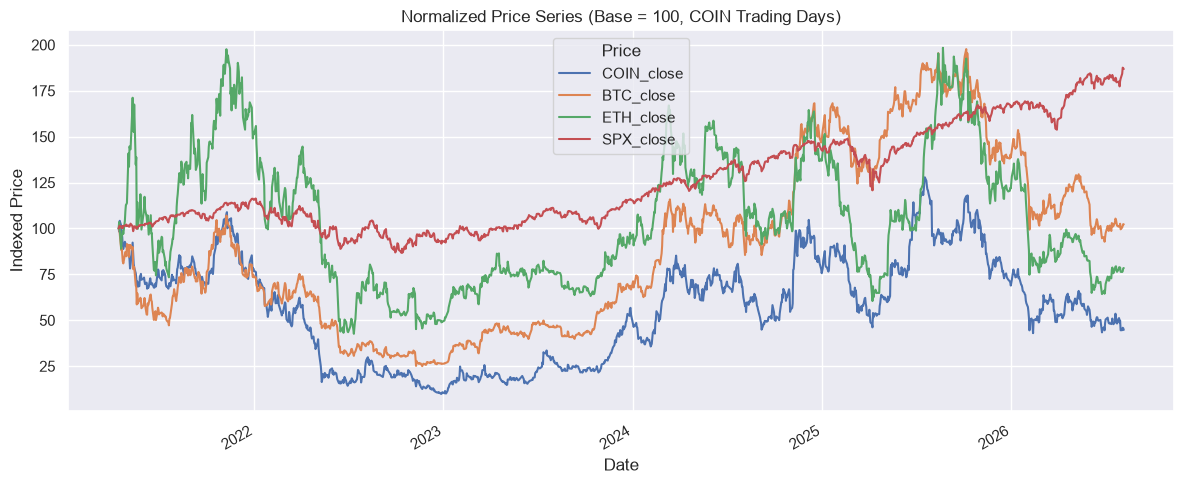

In [4]:
close_cols = [c for c in prices.columns if c.endswith("_close")]
norm = prices[close_cols].dropna()
norm = norm / norm.iloc[0] * 100

ax = norm.plot(title="Normalized Price Series (Base = 100, COIN Trading Days)")
ax.set_ylabel("Indexed Price")
plt.tight_layout()
plt.show()


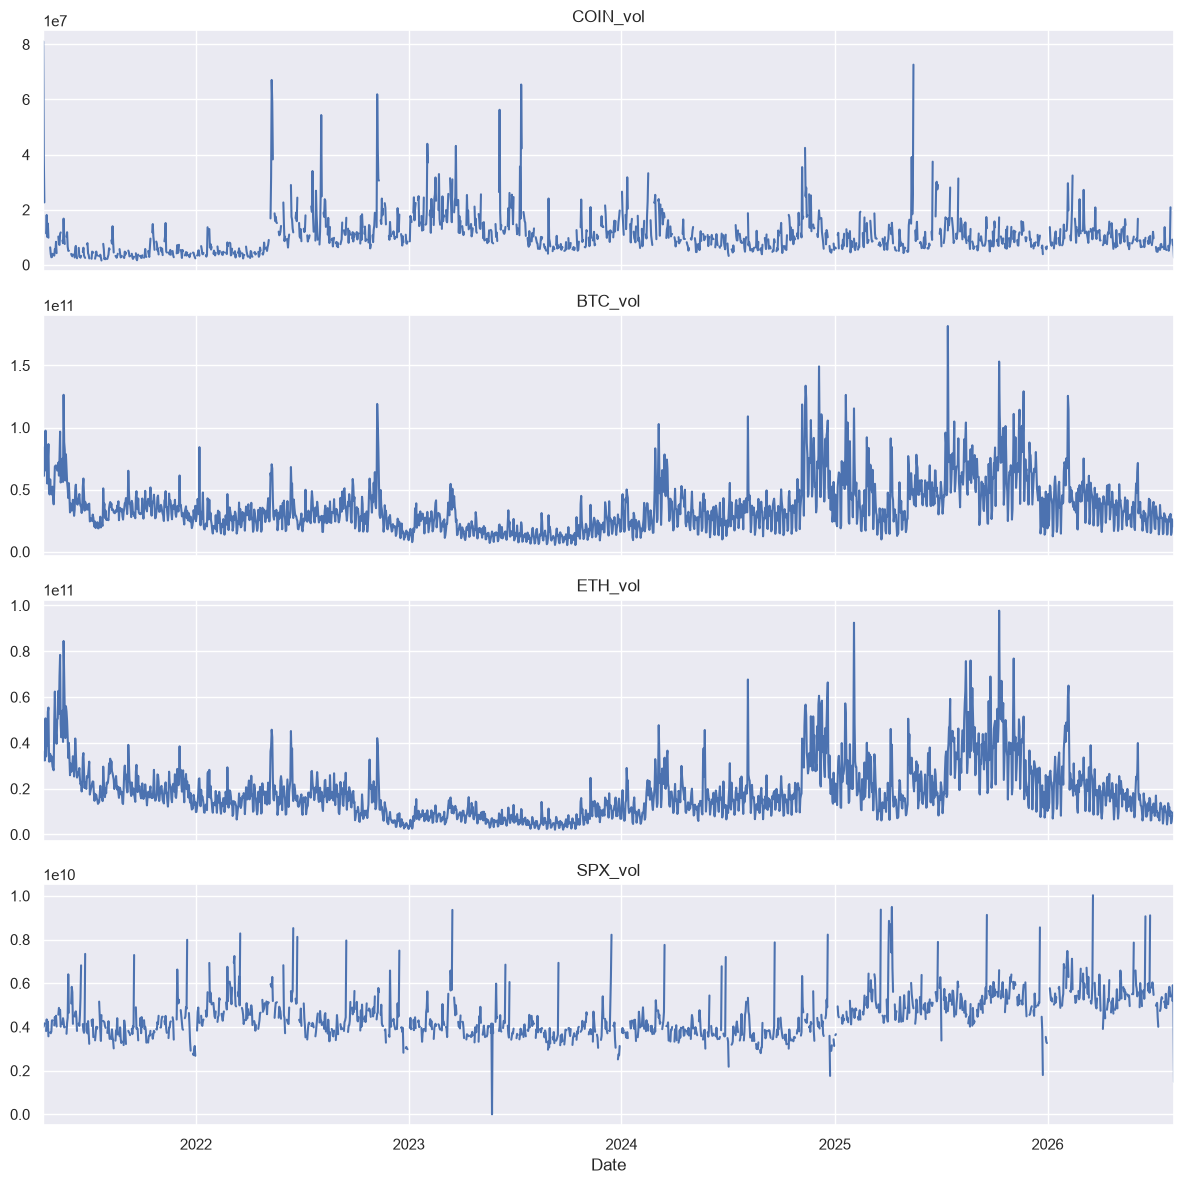

In [5]:
vol_cols = [c for c in prices_full.columns if c.endswith("_vol")]
fig, axes = plt.subplots(len(vol_cols), 1, figsize=(12, 3 * len(vol_cols)), sharex=True)
for ax, col in zip(axes, vol_cols):
    prices_full[col].plot(ax=ax, title=col)
plt.tight_layout()
plt.show()


## 3. Returns & Correlation

Daily log returns are the base unit for everything downstream (correlation, beta, backtests).


In [6]:
rets = pd.DataFrame(index=prices.index)
for col in close_cols:
    name = col.replace("_close", "")
    rets[f"{name}_ret"] = np.log(prices[col]).diff()

rets = rets.dropna(how="all")
rets.tail()


,COIN_ret,BTC_ret,ETH_ret,SPX_ret
Date,,,,
2026-07-31,-0.1119,-0.0300,-0.0302,0.0070
2026-08-03,0.0016,0.0103,-0.0011,0.0147
2026-08-04,0.0285,0.0093,0.0054,0.0177
2026-08-05,-0.0056,0.0084,0.0202,-0.0017
2026-08-06,-0.0195,-0.0011,0.0021,-0.0024


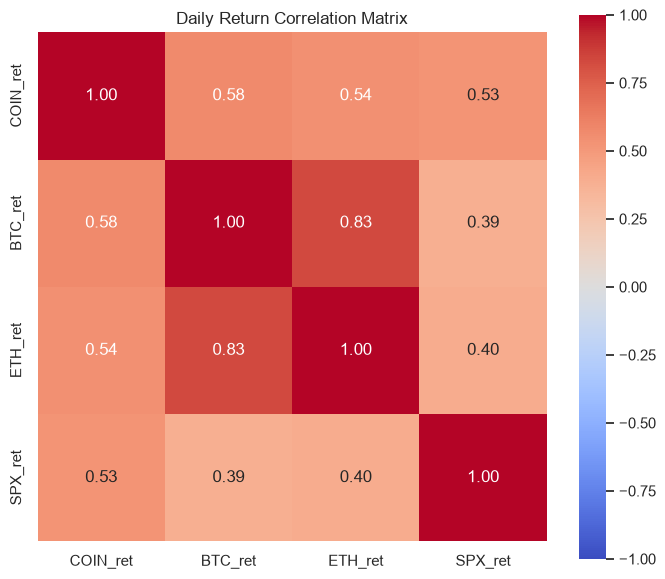

,COIN_ret,BTC_ret,ETH_ret,SPX_ret
COIN_ret,1.0000,0.5776,0.5421,0.5306
BTC_ret,0.5776,1.0000,0.8344,0.3880
ETH_ret,0.5421,0.8344,1.0000,0.4049
SPX_ret,0.5306,0.3880,0.4049,1.0000


In [7]:
corr = rets.corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Daily Return Correlation Matrix")
plt.tight_layout()
plt.show()
corr


**Read this carefully**: if COIN's correlation to BTC/ETH is similar to its correlation to SPX, that
suggests COIN is mostly trading as a high-beta risk asset in general, not specifically a crypto proxy.
The gap between `COIN_ret` vs `BTC_ret` correlation and `COIN_ret` vs `SPX_ret` correlation is the
interesting number.


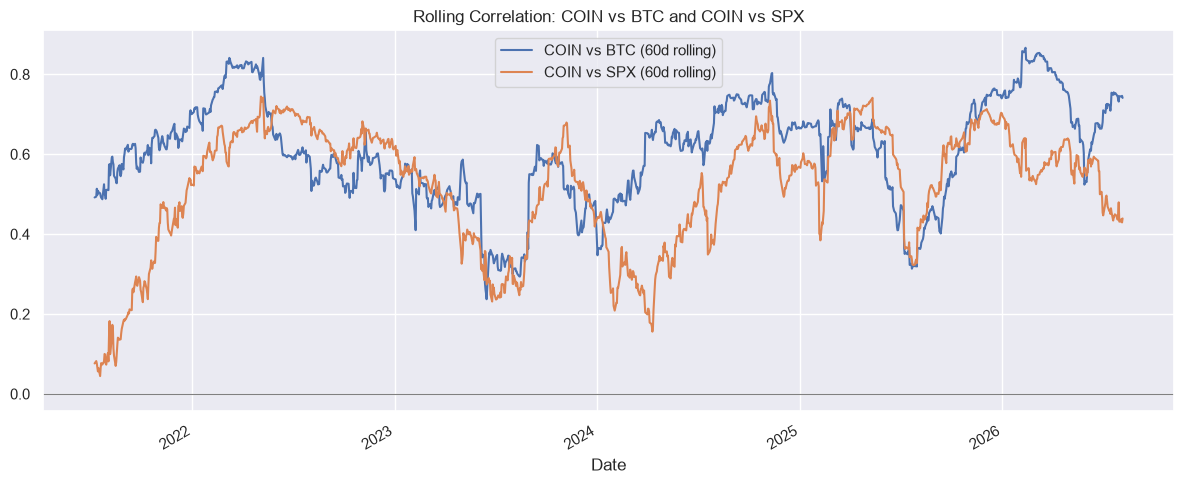

In [8]:
window = 60  # ~3 trading months
roll_corr_btc = rets["COIN_ret"].rolling(window).corr(rets["BTC_ret"])
roll_corr_spx = rets["COIN_ret"].rolling(window).corr(rets["SPX_ret"])

fig, ax = plt.subplots()
roll_corr_btc.plot(ax=ax, label=f"COIN vs BTC ({window}d rolling)")
roll_corr_spx.plot(ax=ax, label=f"COIN vs SPX ({window}d rolling)")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Rolling Correlation: COIN vs BTC and COIN vs SPX")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Lead-Lag Analysis (Trading Edge Candidate #1)

Crypto trades 24/7; COIN only trades during US market hours. That structural gap means crypto price
action over nights/weekends may already be "known information" by the time COIN opens. We test this
with a lagged cross-correlation: does `BTC_ret` at lag *k* predict `COIN_ret` at lag 0 better than
contemporaneous correlation?


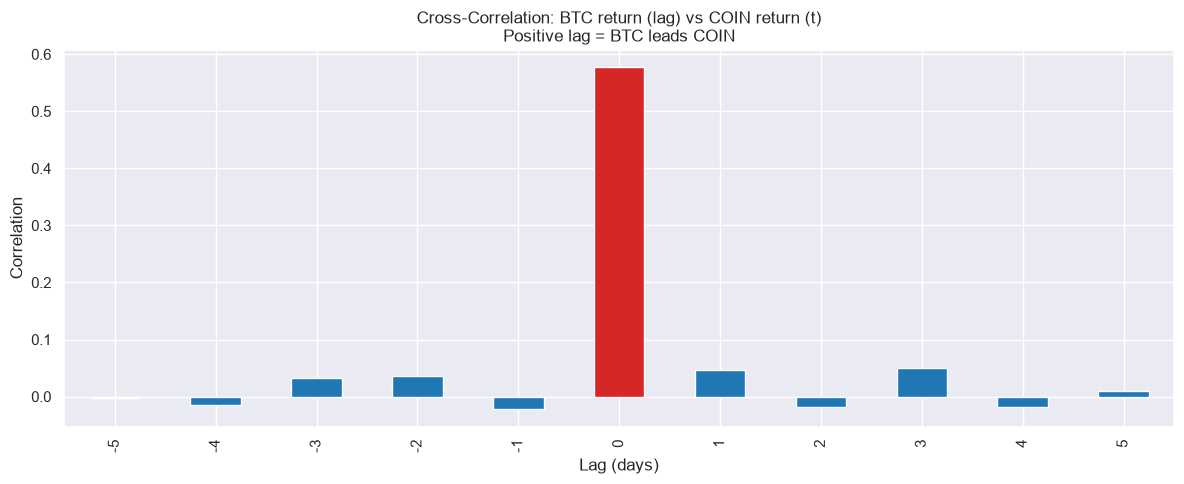

Strongest lag: 0 -> corr = 0.5776251240673248


In [9]:
def lagged_corr(y, x, max_lag=5):
    """Correlation of x shifted by lag with y, for lag in [-max_lag, max_lag].
    Positive lag = x LEADS y (x's past value predicts y's current value)."""
    out = {}
    for lag in range(-max_lag, max_lag + 1):
        out[lag] = y.corr(x.shift(lag))
    return pd.Series(out)

max_lag = 5
ll_btc_leads_coin = lagged_corr(rets["COIN_ret"], rets["BTC_ret"], max_lag)

fig, ax = plt.subplots()
ll_btc_leads_coin.plot(kind="bar", ax=ax, color=["#d62728" if l == 0 else "#1f77b4" for l in ll_btc_leads_coin.index])
ax.set_title("Cross-Correlation: BTC return (lag) vs COIN return (t)\nPositive lag = BTC leads COIN")
ax.set_xlabel("Lag (days)")
ax.set_ylabel("Correlation")
plt.tight_layout()
plt.show()

print("Strongest lag:", ll_btc_leads_coin.abs().idxmax(), "-> corr =", ll_btc_leads_coin.abs().max())


Correlation (weekend BTC move -> Monday COIN return): 0.703


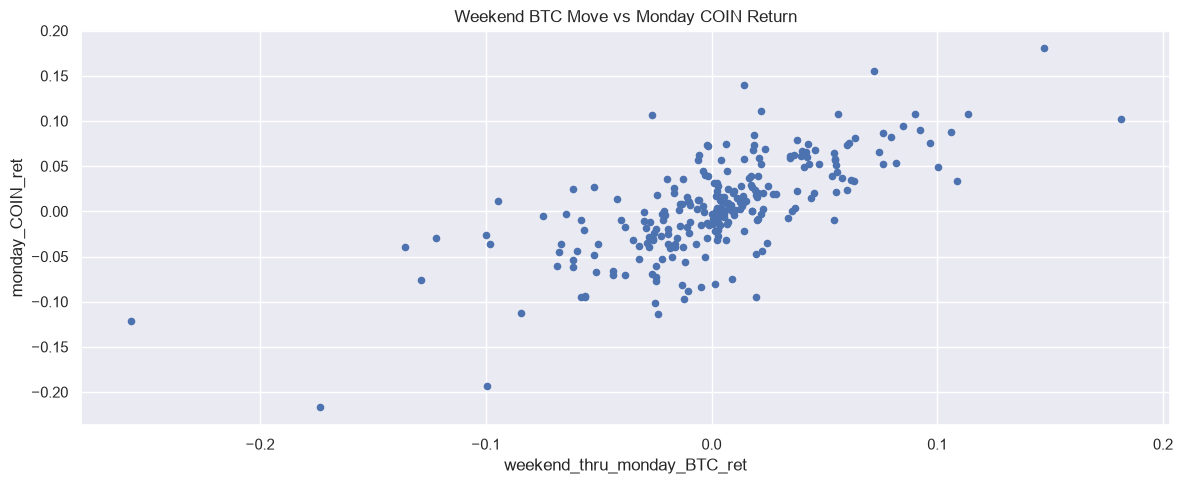

In [10]:
# Specifically test the "weekend gap" hypothesis: BTC's Fri-close-to-Mon-open move vs COIN's Fri-to-Mon return.
weekend = rets.copy()
weekend["dow"] = weekend.index.dayofweek  # Monday=0
monday_coin_ret = weekend.loc[weekend["dow"] == 0, "COIN_ret"]

# BTC return accumulated from Friday close through Sunday close (i.e., over the weekend, before Monday's COIN session)
# Uses prices_full (full 7-day calendar) since that's the whole point of this test.
btc_close = prices_full["BTC_close"]
btc_daily_ret = np.log(btc_close).diff()
weekend_btc_ret = btc_daily_ret.reindex(monday_coin_ret.index)  # Monday's own BTC ret as a same-day check
friday_to_monday_btc = np.log(btc_close).diff(3).reindex(monday_coin_ret.index)  # captures Sat+Sun+Mon move

comp = pd.DataFrame({
    "monday_COIN_ret": monday_coin_ret,
    "weekend_thru_monday_BTC_ret": friday_to_monday_btc,
}).dropna()

print(f"Correlation (weekend BTC move -> Monday COIN return): {comp.corr().iloc[0,1]:.3f}")
comp.plot.scatter(x="weekend_thru_monday_BTC_ret", y="monday_COIN_ret", title="Weekend BTC Move vs Monday COIN Return")
plt.tight_layout()
plt.show()


## 5. Statistical Causality Check: Granger Causality

Correlation doesn't establish direction. Granger causality tests whether past values of one series
help predict another beyond the second series' own history. This is a statistical notion of
"causality," not a economic/mechanistic one — treat it as a filter, not proof.


In [11]:
from statsmodels.tsa.stattools import grangercausalitytests

gc_data = rets[["COIN_ret", "BTC_ret"]].dropna()

print("Does BTC_ret Granger-cause COIN_ret? (columns order: [COIN_ret, BTC_ret])")
gc_results = grangercausalitytests(gc_data, maxlag=5, verbose=True)


Does BTC_ret Granger-cause COIN_ret? (columns order: [COIN_ret, BTC_ret])

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=4.2731  , p=0.0389  , df_denom=1330, df_num=1
ssr based chi2 test:   chi2=4.2828  , p=0.0385  , df=1
likelihood ratio test: chi2=4.2759  , p=0.0387  , df=1
parameter F test:         F=4.2731  , p=0.0389  , df_denom=1330, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=2.7893  , p=0.0618  , df_denom=1327, df_num=2
ssr based chi2 test:   chi2=5.5997  , p=0.0608  , df=2
likelihood ratio test: chi2=5.5879  , p=0.0612  , df=2
parameter F test:         F=2.7893  , p=0.0618  , df_denom=1327, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=2.8418  , p=0.0367  , df_denom=1324, df_num=3
ssr based chi2 test:   chi2=8.5706  , p=0.0356  , df=3
likelihood ratio test: chi2=8.5431  , p=0.0360  , df=3
parameter F test:         F=2.8418  , p=0.0367  , df_denom=1324, df_num=3

Granger Causa

## 6. Volume-Based Synthetic Metrics

Ideas:
- **Relative volume (RVOL)**: today's volume vs. its own trailing average — flags unusual activity.
- **Cross-asset volume ratio**: COIN volume relative to BTC's implied trading activity — a rough proxy
  for "is retail/institutional flow rotating into the equity vs. the coin itself."
- Do COIN RVOL spikes predict next-day crypto volatility (informed-flow hypothesis), or does it work
  the other way around?


Correlation: COIN RVOL today vs BTC realized vol over next 5 days: 0.018


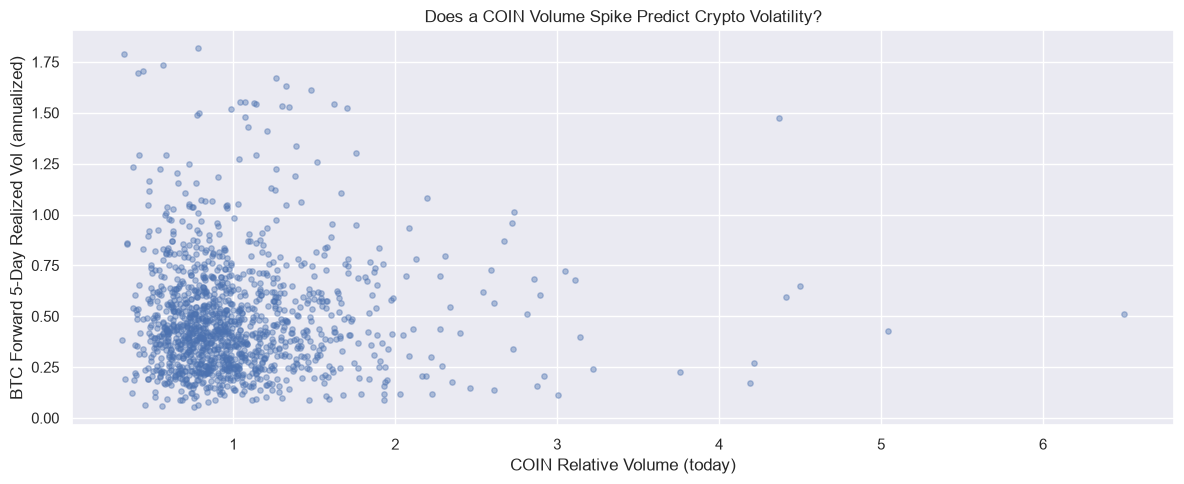

In [12]:
def rvol(vol_series, window=20):
    return vol_series / vol_series.rolling(window).mean()

coin_rvol = rvol(prices["COIN_vol"])
btc_rvol = rvol(prices["BTC_vol"])

realized_vol_btc = rets["BTC_ret"].rolling(5).std() * np.sqrt(252)  # annualized 5d realized vol

merged = pd.DataFrame({
    "coin_rvol": coin_rvol,
    "btc_rvol": btc_rvol,
    "btc_fwd_vol_5d": realized_vol_btc.shift(-5),  # crypto vol over the NEXT 5 days
}).dropna()

print("Correlation: COIN RVOL today vs BTC realized vol over next 5 days:",
      round(merged["coin_rvol"].corr(merged["btc_fwd_vol_5d"]), 3))

fig, ax = plt.subplots()
ax.scatter(merged["coin_rvol"], merged["btc_fwd_vol_5d"], alpha=0.4, s=15)
ax.set_xlabel("COIN Relative Volume (today)")
ax.set_ylabel("BTC Forward 5-Day Realized Vol (annualized)")
ax.set_title("Does a COIN Volume Spike Predict Crypto Volatility?")
plt.tight_layout()
plt.show()


In [13]:
# Bucket analysis: split into COIN RVOL quintiles, look at avg forward crypto vol per bucket
merged["rvol_quintile"] = pd.qcut(merged["coin_rvol"], 5, labels=[f"Q{i+1}" for i in range(5)], duplicates="drop")
bucket_stats = merged.groupby("rvol_quintile", observed=True)["btc_fwd_vol_5d"].agg(["mean", "std", "count"])
bucket_stats


,mean,std,count
rvol_quintile,,,
Q1,0.5042,0.2903,263
Q2,0.4718,0.2549,262
Q3,0.4545,0.2129,262
Q4,0.4585,0.2803,262
Q5,0.5142,0.3088,262


## 7. COIN as a Levered Beta on Crypto

If COIN behaves like operating leverage on crypto trading volumes (its revenue is largely
transaction-fee based), its rolling beta to BTC could be systematically **> 1**, and shifts in that
beta might itself be a signal (e.g., beta compressing ahead of a re-rating).


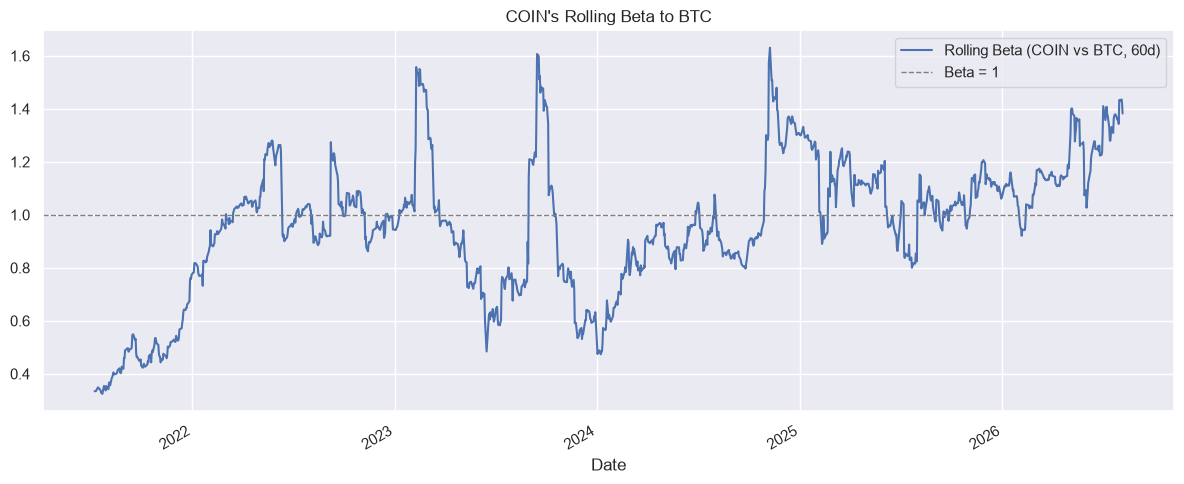

Average beta over full sample: 0.96
% of days beta > 1: 44.0%


In [14]:
def rolling_beta_alpha(y, x, window=60):
    """Rolling OLS beta/alpha of y on x."""
    cov = y.rolling(window).cov(x)
    var = x.rolling(window).var()
    beta = cov / var
    alpha = y.rolling(window).mean() - beta * x.rolling(window).mean()
    return beta, alpha

beta, alpha = rolling_beta_alpha(rets["COIN_ret"], rets["BTC_ret"], window=60)

fig, ax = plt.subplots()
beta.plot(ax=ax, label="Rolling Beta (COIN vs BTC, 60d)")
ax.axhline(1, color="gray", linestyle="--", linewidth=1, label="Beta = 1")
ax.set_title("COIN's Rolling Beta to BTC")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Average beta over full sample: {beta.mean():.2f}")
print(f"% of days beta > 1: {(beta > 1).mean() * 100:.1f}%")


## 8. Mean Reversion: COIN / BTC Ratio Z-Score

A classic pairs-trading construct: if COIN and BTC are cointegrated-ish over medium windows, extreme
deviations in their price ratio (z-scored) may mean-revert. This is a hypothesis to validate, not a
guarantee — COIN and BTC are not the same asset and can permanently re-rate relative to each other
(e.g. on regulatory news specific to Coinbase).


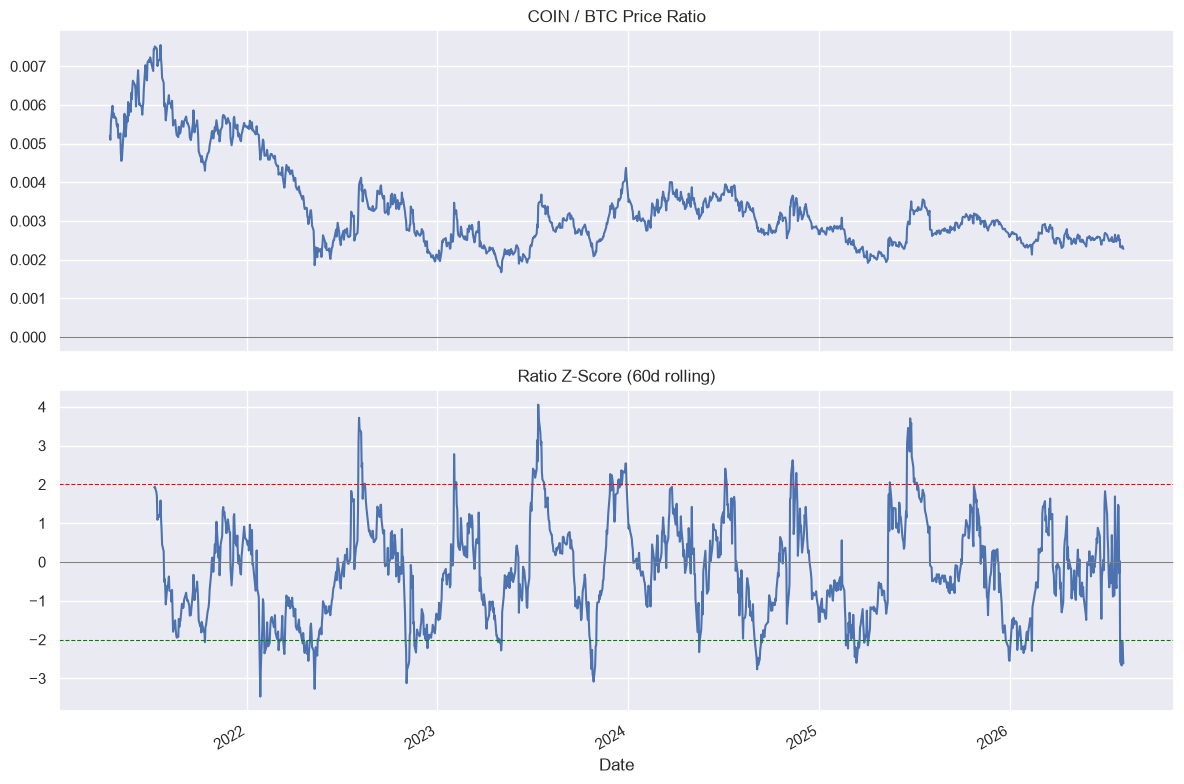

In [15]:
ratio = prices["COIN_close"] / prices["BTC_close"]
window = 60
ratio_z = (ratio - ratio.rolling(window).mean()) / ratio.rolling(window).std()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ratio.plot(ax=axes[0], title="COIN / BTC Price Ratio")
ratio_z.plot(ax=axes[1], title=f"Ratio Z-Score ({window}d rolling)")
for ax in axes:
    ax.axhline(0, color="gray", linewidth=0.8)
axes[1].axhline(2, color="red", linestyle="--", linewidth=0.8)
axes[1].axhline(-2, color="green", linestyle="--", linewidth=0.8)
plt.tight_layout()
plt.show()


In [16]:
from statsmodels.tsa.stattools import adfuller

adf_stat, p_value, *_ = adfuller(ratio.dropna())
print(f"ADF test on COIN/BTC ratio: statistic={adf_stat:.3f}, p-value={p_value:.4f}")
print("p < 0.05 suggests the ratio is stationary (mean-reverting) over this sample;"
      " p > 0.05 means we can't reject a random walk / trending relationship.")


ADF test on COIN/BTC ratio: statistic=-2.577, p-value=0.0979
p < 0.05 suggests the ratio is stationary (mean-reverting) over this sample; p > 0.05 means we can't reject a random walk / trending relationship.


## 9. Simple Signal Backtest (Illustrative Only)

Two toy strategies to sanity-check whether any of the above translates into a return edge:

1. **Lag strategy**: go long/short COIN based on the sign of BTC's return over the prior N days
   (tests the lead-lag hypothesis from Section 4).
2. **Mean-reversion strategy**: fade extreme COIN/BTC ratio z-scores (tests Section 8).

No transaction costs, slippage, borrow fees, or position sizing are modeled — this is purely to see if
there's *any* raw signal before investing more research effort.


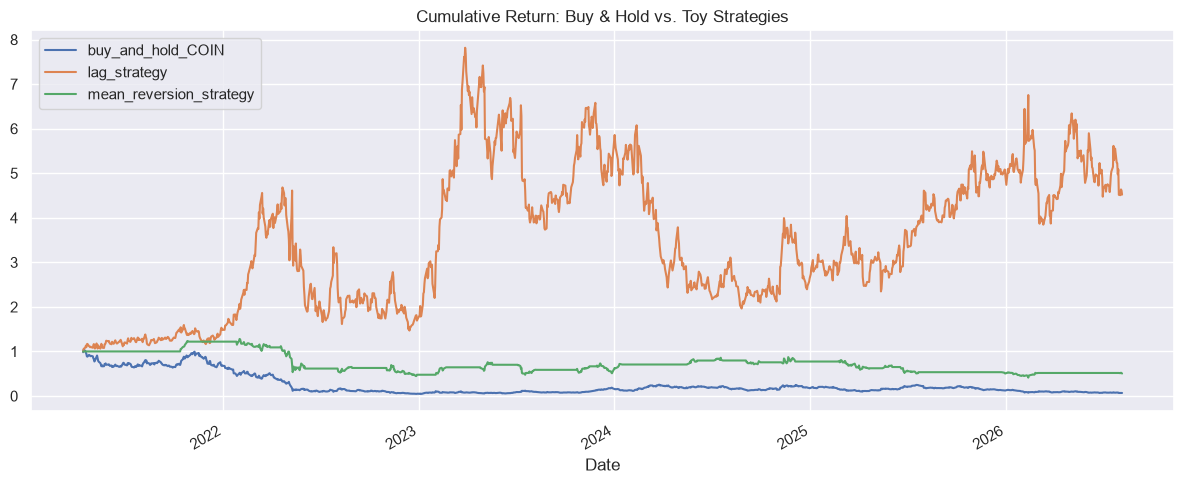

,annualized_sharpe,total_return,annualized_vol
buy_and_hold_COIN,-0.1803,-0.9319,0.8420
lag_strategy,0.7609,3.5205,0.8414
mean_reversion_strategy,-0.1159,-0.4947,0.4032


In [17]:
def sharpe(returns, periods_per_year=252):
    r = returns.dropna()
    if r.std() == 0 or len(r) == 0:
        return np.nan
    return (r.mean() / r.std()) * np.sqrt(periods_per_year)

# --- Strategy 1: lag signal (BTC's prior-day return sign predicts COIN's next return) ---
signal_lag = np.sign(rets["BTC_ret"].shift(1))
strat1_ret = signal_lag * rets["COIN_ret"]

# --- Strategy 2: mean reversion on ratio z-score ---
entry_z = 2.0
signal_mr = pd.Series(0.0, index=ratio_z.index)
signal_mr[ratio_z > entry_z] = -1.0   # ratio too high -> short COIN / long BTC (short the spread)
signal_mr[ratio_z < -entry_z] = 1.0   # ratio too low -> long COIN / long the spread
signal_mr = signal_mr.replace(0, np.nan).ffill(limit=10).fillna(0)  # hold position for up to 10 days
strat2_ret = signal_mr.shift(1) * (rets["COIN_ret"] - rets["BTC_ret"])

buy_hold = rets["COIN_ret"]

results = pd.DataFrame({
    "buy_and_hold_COIN": buy_hold,
    "lag_strategy": strat1_ret,
    "mean_reversion_strategy": strat2_ret,
}).dropna(how="all")

cum = (1 + results.fillna(0)).cumprod()
cum.plot(title="Cumulative Return: Buy & Hold vs. Toy Strategies")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "annualized_sharpe": results.apply(sharpe),
    "total_return": cum.iloc[-1] - 1,
    "annualized_vol": results.std() * np.sqrt(252),
})
summary


## 10. Takeaways & Next Steps

Fill this in as you iterate, but starting points to dig deeper on whatever looks promising above:

- **If the weekend-gap lead-lag effect is real**: test it out-of-sample, check whether it's decayed
  over time (crypto/equity market efficiency tends to erode gaps like this once known), and account for
  COIN's actual overnight/weekend gap-open behavior (not just log returns).
- **If rolling beta shows structure**: investigate whether beta regime changes correlate with COIN
  fundamentals (trading volume/revenue guidance, regulatory news, ETF flow days) rather than pure
  price action — that's a more defensible source of edge than price-only signals.
- **If the COIN/BTC ratio is stationary**: extend to a proper cointegration test (Engle-Granger or
  Johansen) and build a real pairs-trade sizing/risk framework (this rough z-score entry is a toy).
- **Add more synthetic metrics**: options-implied vol on COIN (if available), COIN short interest,
  stablecoin supply growth, exchange netflows (Glassnode/CryptoQuant if you have API access), BTC
  dominance, and funding rates on perp futures as sentiment proxies.
- **Robustness**: everything above should be re-run on rolling out-of-sample windows and with
  transaction-cost-adjusted backtests before treating any of it as an actual edge.
